**Question 1 - Linear Models and Maximum Likelihood**

Import libraries and data

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../Data/HW2_q1_data.csv")

#Load the variables `x1` and `y1` from `HW2_q1_data.csv`.
# This data represents the stimulus (x1) and the measured firing rate (y1) of a neuron with normally distributed noise.
x1 = df['x1'].to_numpy()
y1 = df['y1'].to_numpy()

a)\
Use the analytical solution for linear regression to find the best estimates for the slope (θ1) and the intercept (θ0). What are they?


In [16]:
mean_x1 = x1.mean()
mean_y1 = y1.mean()

#Finding the slope by the analytical solution:
b1_numerator = 0
b1_denominator = 0
for i in np.arange(len(x1)):
    b1_numerator += (x1[i]-mean_x1)*(y1[i]-mean_y1)
    b1_denominator += (x1[i]-mean_x1)**2
slope = b1_numerator/b1_denominator
intercept = mean_y1 - slope * mean_x1

print(f"By the analytical solution for linear regression the slope is {slope} and intercept is {intercept}.")

By the analytical solution for linear regression the slope is 2.8840332010163547 and intercept is 10.128886184405948.


b)\
Implement a numerical solution (e.g., Gradient Descent) to find the best estimates for the parameters. State your chosen learning rate and number of iterations/epochs. How do these results compare to the analytical solution?


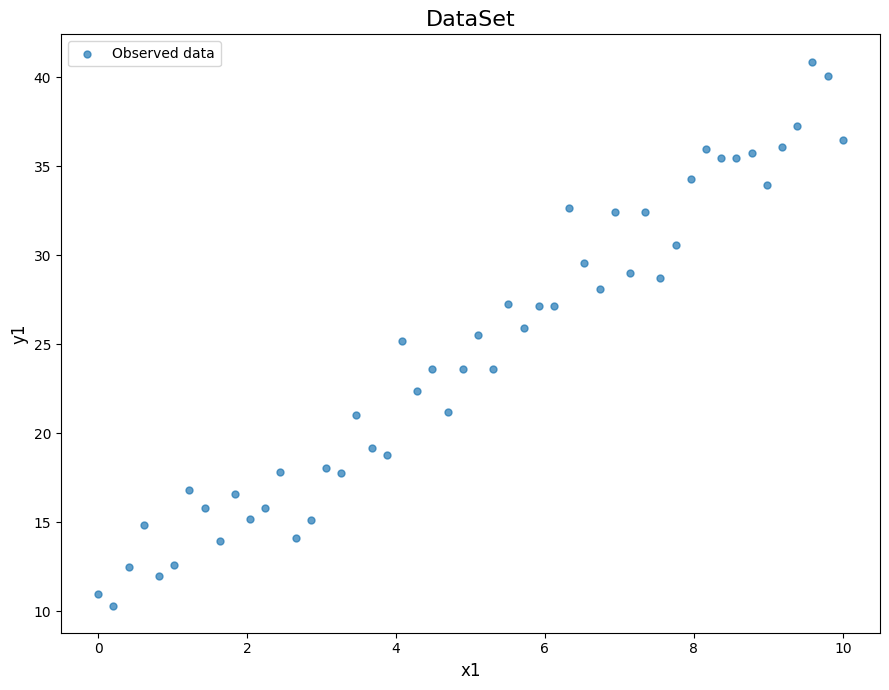

Best tested beta_0: 10.140140140140142
Best tested beta_1: 2.8828828828828836
Minimum MSE: 3.300608933476541


/var/folders/py/3jgx267n73362tsn4ft78rfh0000gn/T/ipykernel_31582/978023717.py:347: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


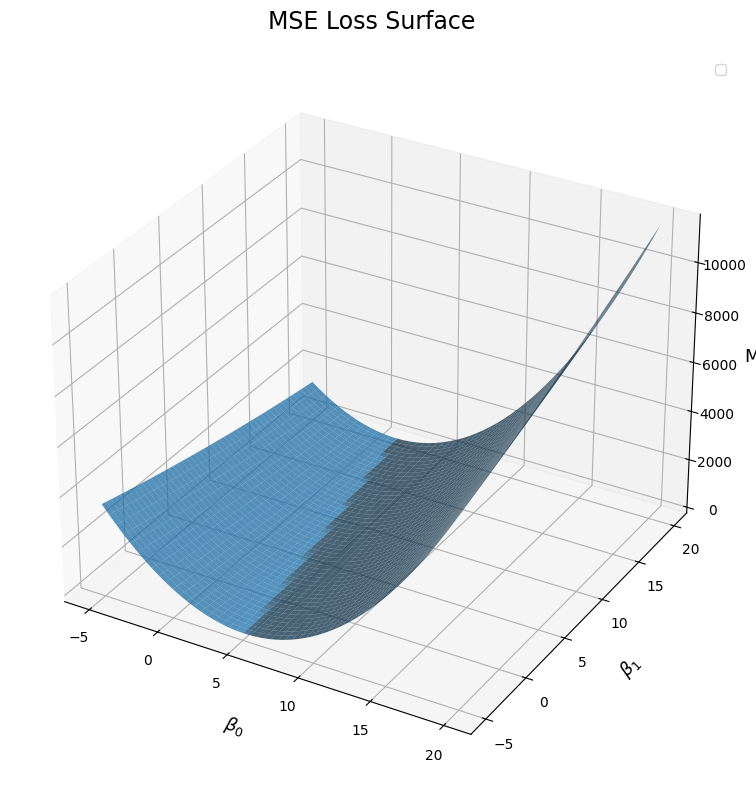

In [28]:
# ============================================================
# OPTIMIZING A ONEDIMENSIONAL LINEAR MODEL
# ============================================================
#
# Model:
#
#       y = beta_0 + beta_1*x1
#
# We will:
#
#   1. Generate a dataset with a known linear relationship
#   2. Choose many possible values of beta_1 and beta_2
#   3. Calculate the MSE manually for EVERY combination
#   4. Plot the MSE as a function of beta_1 and beta_2
#
#
# IMPORTANT:
#
# We are NOT using:
#
#       LinearRegression()
#       mean_squared_error()
#       scipy.optimize()
#
# We calculate everything ourselves.
#
# ============================================================


# ============================================================
# 1. Generate the dataset
# ============================================================
#
# We will assume that the "true" relationship is:
#
#       y = 4 + 3*x1
#
# Therefore:
#
#       beta_0 = 4
#       beta_1 = 3
#
# ============================================================


# ============================================================
# 2. Plot the generated dataset
# ============================================================

fig = plt.figure(
    figsize=(9, 7)
)

ax = fig.add_subplot(
    111,
)

ax.scatter(
    x1,
    y1,
    s=25,
    alpha=0.7,
    label="Observed data"
)

ax.set_title(
    "DataSet",
    fontsize=16
)

ax.set_xlabel(
    "x1",
    fontsize=12
)

ax.set_ylabel(
    "y1",
    fontsize=12
)


ax.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 3. Define possible values of beta_1
# ============================================================
#
# Instead of optimizing beta_1 using an algorithm,
# we will simply TRY many different values.
#
# For example:
#
#       beta_1 = -1.0
#       beta_1 = -0.9
#       beta_1 = -0.8
#       ...
#       beta_1 = 5.0
#
# and the same for beta_2.
#
# Every combination gives us a different model.
# ============================================================


beta_0_values = np.linspace(
    -5,
    20,
    1000
)

beta_1_values = np.linspace(
    -5,
    20,
    1000
)


# Create a grid containing EVERY combination
# of beta_0 and beta_1

beta_0_grid, beta_1_grid = np.meshgrid(
    beta_0_values,
    beta_1_values
)


# ============================================================
# 4. Create an array to store the MSE
# ============================================================

MSE = np.zeros(
    beta_0_grid.shape
)


# ============================================================
# 5. Calculate the MSE manually
# ============================================================
#
# For every possible pair:
#
#       beta_1
#       beta_2
#
# we calculate:
#
#       y_pred = beta_0 + beta_1*x1 + beta_2*x2
#
# followed by:
#
#       residual = y - y_pred
#
# and finally:
#
#       MSE = mean(residual^2)
#
# ============================================================


for i in range(len(beta_1_values)):

    for j in range(len(beta_0_values)):

        # ----------------------------------------------------
        # Current parameter values
        # ----------------------------------------------------

        beta_0 = beta_0_values[j]
        beta_1 = beta_1_values[i]


        # ----------------------------------------------------
        # Calculate model prediction
        # ----------------------------------------------------

        y_pred = (
            beta_0
            + beta_1 * x1
        )


        # ----------------------------------------------------
        # Calculate residuals
        # ----------------------------------------------------
        #
        # Residual:
        #
        #       observed y - predicted y
        #
        # ----------------------------------------------------

        residuals = y1 - y_pred


        # ----------------------------------------------------
        # Calculate MSE manually
        # ----------------------------------------------------

        mse = np.mean(
            residuals ** 2
        )


        # ----------------------------------------------------
        # Store the MSE
        # ----------------------------------------------------

        MSE[i, j] = mse


# ============================================================
# 6. Find the minimum MSE
# ============================================================
#
# We can now find which parameter combination gave
# the smallest MSE.
#
# This is NOT an optimization algorithm.
#
# We are simply searching through all the values
# that we manually tested.
# ============================================================


minimum_index = np.unravel_index(
    np.argmin(MSE),
    MSE.shape
)


best_beta_0 = beta_0_values[
    minimum_index[1]
]

best_beta_1 = beta_1_values[
    minimum_index[0]
]

minimum_MSE = MSE[
    minimum_index
]


print(
    "Best tested beta_0:",
    best_beta_0
)

print(
    "Best tested beta_1:",
    best_beta_1
)

print(
    "Minimum MSE:",
    minimum_MSE
)


# ============================================================
# 7. Plot the MSE surface
# ============================================================
#
# This is the important visualization.
#
# x-axis:
#
#       beta_1
#
# y-axis:
#
#       beta_2
#
# z-axis:
#
#       MSE
#
# Each point on this surface represents the error
# produced by ONE possible pair of parameters.
# ============================================================


fig = plt.figure(
    figsize=(11, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# ------------------------------------------------------------
# Plot the MSE surface
# ------------------------------------------------------------

surface = ax.plot_surface(
    beta_1_grid,
    beta_0_grid,
    MSE,
    alpha=0.75
)



# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    r"$\beta_0$",
    fontsize=13,
    labelpad=10
)

ax.set_ylabel(
    r"$\beta_1$",
    fontsize=13,
    labelpad=10
)

ax.set_zlabel(
    "MSE",
    fontsize=13,
    labelpad=10
)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "MSE Loss Surface",
    fontsize=17,
    pad=20
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend()


plt.tight_layout()
plt.show()

c)\
Calculate the Mean Squared Error (MSE) and R2 (explained variance) of your model.

d)\
Assuming the variance of the noise is equal to your calculated MSE, what is the Log-Likelihood (LL) of this model? Show your calculations.

e)\
Plot the data points and your linear fit.

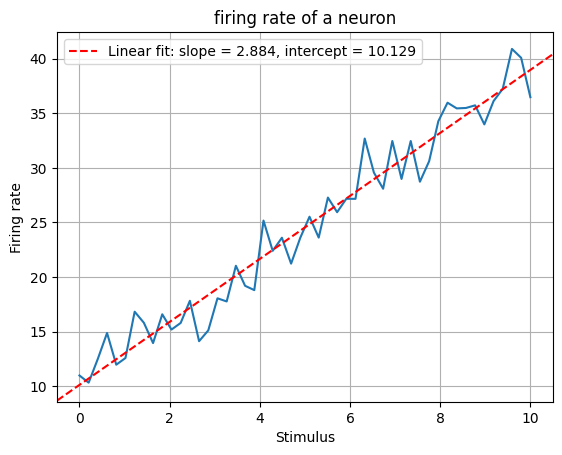

In [26]:
#Draft
plt.figure()
plt.title("firing rate of a neuron")
plt.plot(x1, y1)
plt.axline(xy1 = (0,intercept),slope = slope, color = 'red', linestyle = '--',label = f"Linear fit: slope = {round(slope,3)}, intercept = {round(intercept,3)}")
plt.xlabel("Stimulus")
plt.ylabel("Firing rate")
plt.legend()
plt.grid()
plt.show()